In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import os

sys.path.insert(0, '/home/riley/pc-occlusion-3/kitti')
from inspect_frame import read_labels

DATA_ROOT = Path('/home/riley/OpenPCDet/data/kitti')
os.environ["NUMBA_CUDA_DRIVER"] = "/usr/lib/wsl/lib/libcuda.so.1"

7481
Frame 000000: 1 labels
Frame 000001: 7 labels
Frame 000002: 2 labels
Frame 000003: 3 labels
Frame 000004: 7 labels
Frame 000005: 5 labels
Frame 000006: 6 labels
Frame 000007: 6 labels
Frame 000008: 10 labels
Frame 000009: 5 labels
Frame 000010: 13 labels
Frame 000011: 9 labels
Frame 000012: 5 labels
Frame 000013: 2 labels
Frame 000014: 3 labels
Frame 000015: 10 labels
Frame 000016: 22 labels
Frame 000017: 2 labels
Frame 000018: 20 labels
Frame 000019: 6 labels
Frame 000020: 1 labels
Frame 000021: 10 labels
Frame 000022: 3 labels
Frame 000023: 6 labels
Frame 000024: 7 labels
Frame 000025: 9 labels
Frame 000026: 2 labels
Frame 000027: 3 labels
Frame 000028: 1 labels
Frame 000029: 4 labels
Frame 000030: 2 labels
Frame 000031: 9 labels
Frame 000032: 12 labels
Frame 000033: 3 labels
Frame 000034: 6 labels
Frame 000035: 11 labels
Frame 000036: 9 labels
Frame 000037: 3 labels
Frame 000038: 13 labels
Frame 000039: 8 labels
Frame 000040: 3 labels
Frame 000041: 5 labels
Frame 000042: 6 labe

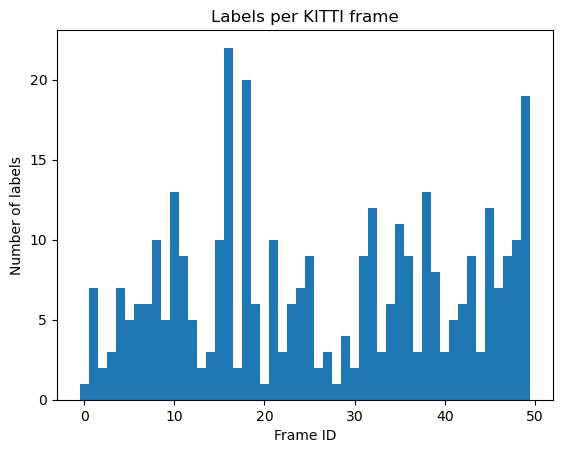

In [2]:
# Make the local helper module importable regardless of the notebook working directory
# frames per kitti 
def inspect(data_root=DATA_ROOT, frame_id='000000', show_plot=False):
    root = data_root / 'training'
    velo_files = sorted((root / 'velodyne').glob('*.bin'))
    print(len(velo_files))
    if not velo_files:
        raise FileNotFoundError(f'No Velodyne files found in {root / "velodyne"}')
    frame_ids = []
    label_counts = []
    for velo_path in velo_files[:50]:
        frame_id = velo_path.stem
        label_path = root / 'label_2' / f'{frame_id}.txt'
        if not label_path.is_file():
            raise FileNotFoundError(f'Missing label file for frame {frame_id}: {label_path}')

        labels = read_labels(label_path)
        print(f'Frame {frame_id}: {len(labels)} labels')
        frame_ids.append(int(frame_id))
        label_counts.append(len(labels))
    
    plt.bar(frame_ids, label_counts, width=1.0)
    plt.xlabel("Frame ID")
    plt.ylabel("Number of labels")
    plt.title("Labels per KITTI frame")
    plt.show()
inspect()


Classes found: ['Car', 'Cyclist', 'DontCare', 'Misc', 'Pedestrian', 'Person_sitting', 'Tram', 'Truck', 'Van']


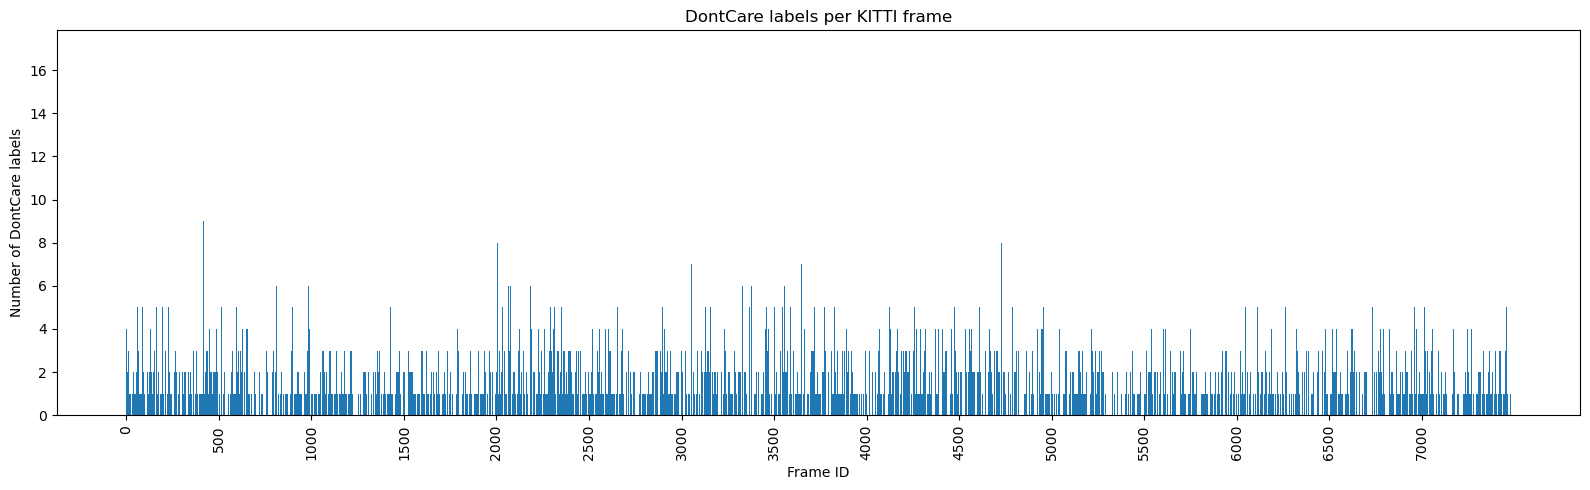

In [3]:
def inspect_dont_care(data_root=DATA_ROOT):
    root = data_root / 'training'
    velo_files = sorted((root / 'velodyne').glob('*.bin'))
    if not velo_files:
        raise FileNotFoundError(f'No Velodyne files found in {root / "velodyne"}')

    frame_ids = []
    dontcare_counts = []
    class_names = set()

    for velo_path in velo_files[:]:
        frame_id = velo_path.stem
        label_path = root / 'label_2' / f'{frame_id}.txt'
        if not label_path.is_file():
            raise FileNotFoundError(f'Missing label file for frame {frame_id}: {label_path}')

        labels = read_labels(label_path)
        # print(f"Frame {frame_id}: {len(labels)} labels; ")
        # for label in labels:
        #     print(label['class'])
        class_names.update(label['class'] for label in labels)
        frame_ids.append(int(frame_id))
        dontcare_counts.append(sum(label['class'] == 'DontCare' for label in labels))
    print('Classes found:', sorted(class_names))

    # print(f'Frames with DontCare: {sum(count > 0 for count in dontcare_counts)}')
    # print(f'Total DontCare labels: {sum(dontcare_counts)}')
    plt.figure(figsize=(16, 5))
    plt.bar(frame_ids, dontcare_counts, width=1.0)
    plt.xlabel('Frame ID')
    plt.ylabel('Number of DontCare labels')
    plt.title('DontCare labels per KITTI frame')
    plt.xticks(frame_ids[::500], rotation=90)
    plt.tight_layout()
    plt.show()

inspect_dont_care()

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Hard-coded settings for one-frame prediction visualization
FRAME_ID = '000001'
DRAW_CLASSES = {'Car', 'Pedestrian', 'Cyclist'}  # e.g. {'Car'}
MIN_CONFIDENCE = 0.10
RAW_DATA_ROOT = Path('/home/riley/OpenPCDet/data/kitti')
PREDICTION_DIR = Path('/home/riley/OpenPCDet/output/kitti_models/pointpillar/default/eval/epoch_no_number/val/baseline_check/final_result/data')

def plot_frame_predictions():
    """Plot one KITTI point cloud with predicted 3-D boxes and labels."""
    root = RAW_DATA_ROOT / 'training'
    points_path = root / 'velodyne' / f'{FRAME_ID}.bin'
    calib_path = root / 'calib' / f'{FRAME_ID}.txt'
    prediction_path = PREDICTION_DIR / f'{FRAME_ID}.txt'
    for path in (points_path, calib_path, prediction_path):
        if not path.is_file():
            raise FileNotFoundError(f'Missing file: {path}')

    points = np.fromfile(points_path, dtype=np.float32).reshape(-1, 4)
    calibration = {}
    for line in calib_path.read_text().splitlines():
        if ':' not in line:
            continue
        name, values = line.split(':', 1)
        numbers = np.fromstring(values, sep=' ')
        if name in {'R0_rect', 'R_rect_00'}:
            calibration['R0'] = numbers.reshape(3, 3)
        elif name in {'Tr_velo_to_cam', 'Tr_velo_cam'}:
            calibration['T'] = numbers.reshape(3, 4)
    if set(calibration) != {'R0', 'T'}:
        raise ValueError(f'Calibration file is missing R0_rect or Tr_velo_to_cam: {calib_path}')

    R0, T = calibration['R0'], calibration['T']
    R = R0 @ T[:, :3]
    t = R0 @ T[:, 3]

    def camera_to_lidar(points_camera):
        return ((R.T @ (points_camera - t).T).T)

    def box_corners_camera(height, width, length, location, rotation_y):
        x, y, z = location
        local = np.array([[ length/2, 0,  width/2], [ length/2, 0, -width/2],
                          [-length/2, 0, -width/2], [-length/2, 0,  width/2],
                          [ length/2, -height,  width/2], [ length/2, -height, -width/2],
                          [-length/2, -height, -width/2], [-length/2, -height,  width/2]])
        c, s = np.cos(rotation_y), np.sin(rotation_y)
        rotation = np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])
        return (rotation @ local.T).T + np.array([x, y, z])

    edges = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6),
             (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]
    figure = plt.figure(figsize=(14, 9))
    axis = figure.add_subplot(111, projection='3d')
    step = max(1, len(points) // 50000)
    axis.scatter(points[::step, 0], points[::step, 1], points[::step, 2], s=0.2, c=points[::step, 3], cmap='viridis')

    drawn = 0
    for line in prediction_path.read_text().splitlines():
        fields = line.split()
        if len(fields) < 16:
            continue
        class_name = fields[0]
        confidence = float(fields[15])
        if class_name not in DRAW_CLASSES or confidence < MIN_CONFIDENCE:
            continue
        height, width, length = map(float, fields[8:11])
        location = tuple(map(float, fields[11:14]))
        rotation_y = float(fields[14])
        corners = camera_to_lidar(box_corners_camera(height, width, length, location, rotation_y))
        for start, end in edges:
            axis.plot(*zip(corners[start], corners[end]), color='red', linewidth=1.5)
        center = corners[:4].mean(axis=0)
        axis.text(*center, f'{class_name} {confidence:.2f}', color='red', fontsize=9)
        drawn += 1

    axis.set_xlabel('LiDAR x (forward, m)')
    axis.set_ylabel('LiDAR y (left, m)')
    axis.set_zlabel('LiDAR z (up, m)')
    axis.set_title(f'Frame {FRAME_ID}: {drawn} predicted boxes')
    plt.show()

plot_frame_predictions()


NameError: name 'Path' is not defined